In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [24]:
from datasets import load_dataset

# Load the Dataset

In [25]:
emotion_dataset = load_dataset('dair-ai/emotion')

In [26]:
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

In [27]:
label_names = emotion_dataset['train'].features['label'].names

In [28]:
df_train = pd.DataFrame(
    {
        'text' : train_text,
        'label' : [label_names[i] for i in train_label]
    }
)

In [29]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [30]:
df_test = pd.DataFrame({
    'text' : test_text,
    'label' : [label_names[i] for i in test_label]
})

In [31]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


In [32]:
df_train.isnull().sum()

text     0
label    0
dtype: int64

# Exploratory Data Analysis (EDA)

In [33]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='str',
      name='label')

<Axes: xlabel='label', ylabel='count'>

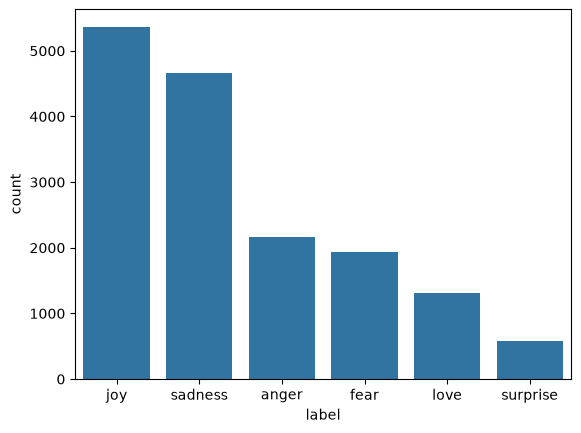

In [34]:
sns.countplot(x = 'label', data = df_train, order = df_train['label'].value_counts().index)

# Data Preprocessing using NLP

In [35]:
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


In [36]:
# Tokenize text
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 10000

tokenizer = Tokenizer(num_words = max_words, oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequence = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence = pad_sequences(train_sequence,maxlen = 50, padding='post', truncating='post')
padded_test_sequence = pad_sequences(test_sequence,maxlen = 50, padding='post', truncating='post')

train_labels = np.array(train_label)
test_labels = np.array(test_label)

num_classes = len(np.unique(train_labels))

print(f"Vocabulary size : {len(tokenizer.word_index)}")
print(f"Max Sentence length : {padded_train_sequence.shape[1]}")

Vocabulary size : 15213
Max Sentence length : 50


# Shared Training Utilities

In [37]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes = np.unique(train_labels),
    y = train_labels
)

class_weight_dict = dict(enumerate(class_weights))

In [38]:
# Early Stopping
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Phase 1 - Plain Foundational Models

In [48]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU

rnn_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    SimpleRNN(units = 128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units = 64),
    Dropout(0.5),
    Dense(units = num_classes, activation='softmax')
])

In [49]:
rnn_model.compile(optimizer='adam', loss = 'sparse_categorical_crossentropy', metrics=['accuracy'])

In [50]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data = [padded_test_sequence, test_labels],
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

Epoch 1/20


500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - accuracy: 0.1496 - loss: 2.0654 - val_accuracy: 0.0355 - val_loss: 1.8609
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.1403 - loss: 1.8830 - val_accuracy: 0.0330 - val_loss: 1.7944
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.1236 - loss: 1.8264 - val_accuracy: 0.1375 - val_loss: 1.7816
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 13s 26ms/step - accuracy: 0.1297 - loss: 1.8058 - val_accuracy: 0.2825 - val_loss: 1.7742
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.1447 - loss: 1.8038 - val_accuracy: 0.2700 - val_loss: 1.7680
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.1416 - loss: 1.8012 - val_accuracy: 0.2720 - val_loss: 1.8135
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 23ms/step - accuracy: 0.1477 - loss: 1.8012 - val_accuracy: 0.2680 - val_loss: 1.8111
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.1496 - loss: 1.8021 - val_accurac

In [51]:
rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_labels)
print(f"RNN Loss : {rnn_loss}")
print(f"RNN Accuracy : {rnn_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2700 - loss: 1.7680
RNN Loss : 1.7680126428604126
RNN Accuracy : 0.27000001072883606


# Model 2 - Standard LSTM

In [52]:
lstm_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    LSTM(units = 128, return_sequences=True),
    Dropout(0.5),
    LSTM(units = 64),
    Dropout(0.5),
    Dense(units = num_classes, activation='softmax')
])

lstm_model.compile(optimizer='adam', loss = 'sparse_categorical_crossentropy', metrics=['accuracy'])


lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data = [padded_test_sequence, test_labels],
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f"LSTM Loss : {lstm_loss}")
print(f"LSTM Accuracy : {lstm_accuracy}")

Epoch 1/20


500/500 ━━━━━━━━━━━━━━━━━━━━ 21s 37ms/step - accuracy: 0.1469 - loss: 1.7947 - val_accuracy: 0.0795 - val_loss: 1.8137
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.1376 - loss: 1.7937 - val_accuracy: 0.3435 - val_loss: 1.7424
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - accuracy: 0.1734 - loss: 1.8010 - val_accuracy: 0.0795 - val_loss: 1.7946
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.1406 - loss: 1.7931 - val_accuracy: 0.3475 - val_loss: 1.7865
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - accuracy: 0.1318 - loss: 1.7920 - val_accuracy: 0.1120 - val_loss: 1.7810
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.3435 - loss: 1.7424
LSTM Loss : 1.7424107789993286
LSTM Accuracy : 0.3434999883174896


# Model 3 - Standard GRU

In [53]:
gru_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    GRU(units = 128, return_sequences=True),
    Dropout(0.5),
    GRU(units = 64),
    Dropout(0.5),
    Dense(units = num_classes, activation='softmax')
])

gru_model.compile(optimizer='adam', loss = 'sparse_categorical_crossentropy', metrics=['accuracy'])


gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data = [padded_test_sequence, test_labels],
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss : {gru_loss}")
print(f"GRU Accuracy : {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 37s 67ms/step - accuracy: 0.1582 - loss: 1.7959 - val_accuracy: 0.1365 - val_loss: 1.8012
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 30s 60ms/step - accuracy: 0.1497 - loss: 1.7950 - val_accuracy: 0.0355 - val_loss: 1.8040
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 37s 73ms/step - accuracy: 0.1530 - loss: 1.7945 - val_accuracy: 0.0330 - val_loss: 1.8129
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 50ms/step - accuracy: 0.1584 - loss: 1.7938 - val_accuracy: 0.0360 - val_loss: 1.8171
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.1365 - loss: 1.8012
GRU Loss : 1.8012447357177734
GRU Accuracy : 0.13650000095367432


# Phase 1 - Ranking & Selection

In [55]:
result_df = pd.DataFrame({
    'model' : ['RNN', 'LSTM', 'GRU'],
    'Test Loss' : [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy' : [rnn_accuracy, lstm_accuracy, gru_accuracy]
})

result_df.sort_values(by = 'Test Accuracy', ascending=False)

,model,Test Loss,Test Accuracy
1,LSTM,1.742411,0.3435
0,RNN,1.768013,0.2700
2,GRU,1.801245,0.1365


# Phase 2 - Advanced Bidirectional GRU

In [ ]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim=max_words, output_dim=300, input_length=50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

BiGRU.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

BiGRU.summary()

c:\Users\chira\anaconda3\envs\hf\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_8 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [57]:
BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data = [padded_test_sequence, test_labels],
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 60s 102ms/step - accuracy: 0.5687 - loss: 1.0287 - val_accuracy: 0.8925 - val_loss: 0.3295
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 57s 114ms/step - accuracy: 0.9181 - loss: 0.2346 - val_accuracy: 0.9230 - val_loss: 0.2211
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 56ms/step - accuracy: 0.9464 - loss: 0.1502 - val_accuracy: 0.9175 - val_loss: 0.2137
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 29s 57ms/step - accuracy: 0.9599 - loss: 0.1112 - val_accuracy: 0.9205 - val_loss: 0.2343
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 29s 59ms/step - accuracy: 0.9696 - loss: 0.0827 - val_accuracy: 0.9190 - val_loss: 0.2868
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 29s 59ms/step - accuracy: 0.9765 - loss: 0.0723 - val_accuracy: 0.9150 - val_loss: 0.3300


In [59]:
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(padded_test_sequence, test_labels)

print(f"Bidirectional GRU Loss : {BiGRU_loss}")
print(f"Bidirectional GRU Accuracy : {BiGRU_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9175 - loss: 0.2137
Bidirectional GRU Loss : 0.21365679800510406
Bidirectional GRU Accuracy : 0.9175000190734863


# Overall Evaluation & Bias Analysis

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step


<Axes: >

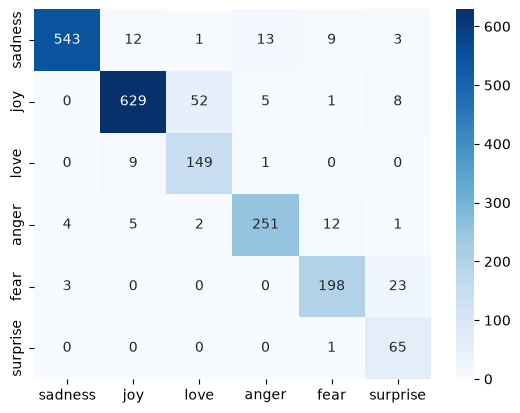

In [67]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequence), axis = 1)

sns.heatmap(confusion_matrix(test_labels, BiGRU_predictions), annot = True, fmt = 'd', cmap = 'Blues', xticklabels=label_names, yticklabels=label_names)

# Final Predictions

In [72]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')
sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis = 1)

for i in range(len(sample_texts)):
    print(f"Text : {sample_texts[i]}\nPredicted Emotion : {label_names[sample_predictions[i]]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Text : I can't believe how happy I am right now, this is amazing!
Predicted Emotion : surprise
Text : I feel so alone and hopeless today.
Predicted Emotion : sadness
Text : I am furious that they cancelled the trip at the last minute.
Predicted Emotion : anger
Text : I feel terrified when walking down dark alleyways alone.
Predicted Emotion : fear
Text : I was shocked and completely surprised by the unexpected gift!
Predicted Emotion : surprise


# Save Model & Tokenizer

In [79]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True)

# Save our BiGRU Model
BiGRU.save(os.path.join(model_dir, 'BiGRU_Model.keras'))
# Save our Tokenizer
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
    pickle.dump(tokenizer, file)